# VG-only vs. VG-flow: Visual Comparison and What NLL Does (and Doesn't) Tell You

This notebook does three things:

1. **Visualize** the fitted VG-only (no-flow) model, the VG-flow model, and the real data together --
   density overlay, log-scale tails, and QQ plots.
2. **Explain empirically** why VG-only's NLL can look so close to VG-flow's, by decomposing NLL
   into a bulk contribution and a tail contribution.
3. **Show directly** that NLL similarity does *not* imply tail similarity, using VaR and a
   tail-restricted comparison as the counter-evidence.

Uses the saved artifacts from `real_data_compare.py` (`sp500_results.npz`, `my_flow_sp500.pt`).

In [1]:
import numpy as np
import torch
import matplotlib.pyplot as plt
from pathlib import Path
import sys
from scipy.stats import ks_2samp

PROJECT_ROOT = next(path for path in (Path.cwd(), *Path.cwd().parents) if (path / "levy_flow").is_dir())
sys.path.insert(0, str(PROJECT_ROOT))

from levy_flow import NSFFlow, VarianceGamma, ks_test, qq_data

plt.rcParams["figure.dpi"] = 100
torch.manual_seed(0)

## 1. Load the trained VG-flow and reconstruct VG-only

In [2]:
d = np.load(PROJECT_ROOT / "results" / "sp500_results.npz")
x_train_raw, x_val_raw = d["x_train_raw"], d["x_val_raw"]
x_mean, x_std = float(d["x_mean"]), float(d["x_std"])
x_train = torch.tensor((x_train_raw - x_mean) / x_std, dtype=torch.float32)
x_val = torch.tensor((x_val_raw - x_mean) / x_std, dtype=torch.float32)

# VG-flow: the jointly-trained (warm-started) model
base = VarianceGamma(mu=0.0, sigma=1.0, theta=0.0, nu=0.5, dtype=torch.float32)
flow = NSFFlow(dim=1, base=base, num_layers=12, num_bins=8, tail_bound=5.0, hidden_dim=128, n_hidden=3)
flow.load_state_dict(torch.load(PROJECT_ROOT / "models" / "my_flow_sp500.pt", weights_only=True))
flow.eval()
print("VG-flow base params:", {k: round(v, 4) for k, v in
      dict(mu=flow.base.mu.item(), sigma=flow.base.sigma.item(),
           theta=flow.base.theta.item(), nu=flow.base.nu.item()).items()})

# VG-only: same grid search as real_data_compare.py, for a clean apples-to-apples comparison
best = None
for theta in [-0.5, -0.3, -0.1, 0.0]:
    for nu in [0.3, 0.5, 0.8, 1.2]:
        cand = VarianceGamma(mu=0.0, sigma=1.0, theta=theta, nu=nu, dtype=torch.float32)
        nll = -cand.log_prob(x_train).mean().item()
        if best is None or nll < best[0]:
            best = (nll, theta, nu)
vg_only = VarianceGamma(mu=0.0, sigma=1.0, theta=best[1], nu=best[2], dtype=torch.float32)
print(f"VG-only (grid search): theta={best[1]}, nu={best[2]}, train NLL={best[0]:.4f}")

VG-flow base params: {'mu': -0.0269, 'sigma': 1.0871, 'theta': 0.0825, 'nu': 1.2595}
VG-only (grid search): theta=0.0, nu=1.2, train NLL=1.2828


## 2. Density Comparison

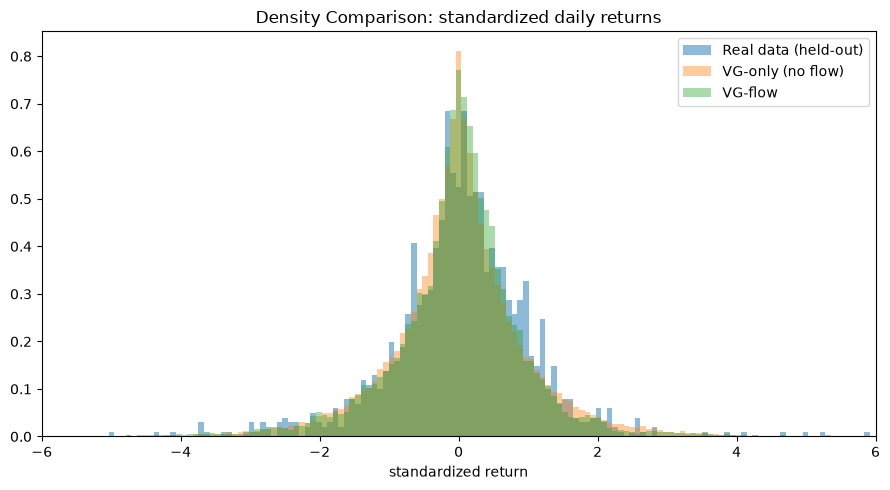

In [3]:
n_samples = 50_000
with torch.no_grad():
    flow_samples = flow.sample(n_samples).numpy().flatten()
    vg_only_samples = vg_only.rsample((n_samples,)).numpy().flatten()

fig, ax = plt.subplots(figsize=(9, 5))
bins = np.linspace(-6, 6, 150)
ax.hist(x_val.numpy(), bins=bins, density=True, alpha=0.5, label="Real data (held-out)")
ax.hist(vg_only_samples, bins=bins, density=True, alpha=0.4, label="VG-only (no flow)")
ax.hist(flow_samples, bins=bins, density=True, alpha=0.4, label="VG-flow")
ax.set_xlim(-6, 6)
ax.set_title("Density Comparison: standardized daily returns")
ax.set_xlabel("standardized return")
ax.legend()
plt.tight_layout()
plt.savefig(PROJECT_ROOT / "results" / "nb_density_comparison.png", dpi=150)
plt.show()

## 3. Log-Scale Tails

This is the more diagnostic version of the same plot -- linear-scale histograms visually compress
the tails to near-invisibility. Log scale is where tail *shape* differences actually become visible.

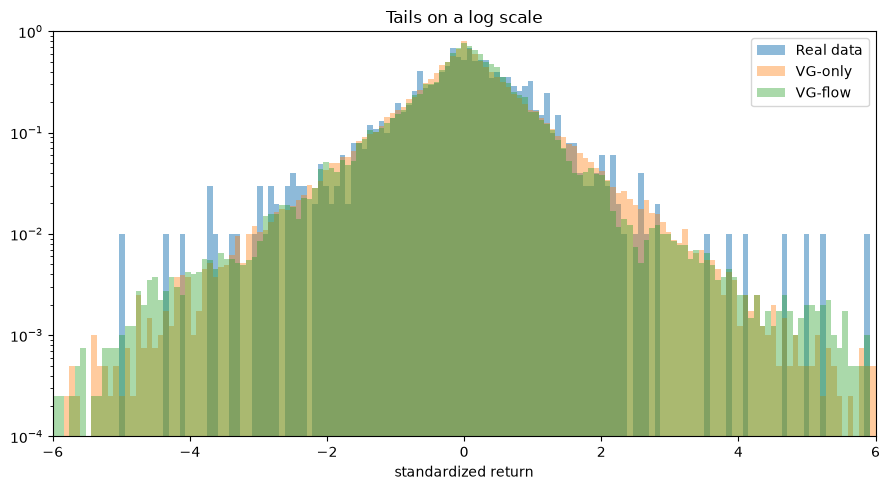

In [4]:
fig, ax = plt.subplots(figsize=(9, 5))
ax.hist(x_val.numpy(), bins=bins, density=True, alpha=0.5, log=True, label="Real data")
ax.hist(vg_only_samples, bins=bins, density=True, alpha=0.4, log=True, label="VG-only")
ax.hist(flow_samples, bins=bins, density=True, alpha=0.4, log=True, label="VG-flow")
ax.set_xlim(-6, 6)
ax.set_ylim(1e-4, 1)
ax.set_title("Tails on a log scale")
ax.set_xlabel("standardized return")
ax.legend()
plt.tight_layout()
plt.savefig(PROJECT_ROOT / "results" / "nb_log_tails.png", dpi=150)
plt.show()

## 4. QQ Plots -- Full Range and Zoomed Tail

The zoomed tail QQ plot is the one that actually answers 'do the tails match', much more directly
than either histogram above.

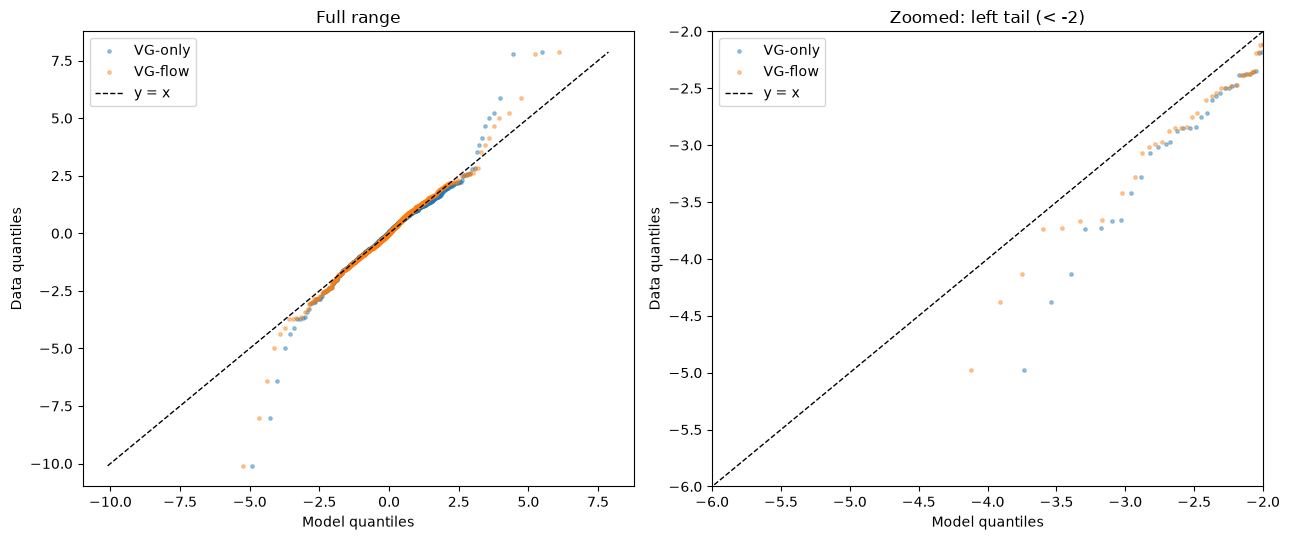

In [5]:
def qq_arrays(samples, data, n_ref=50_000):
    data_sorted = np.sort(data)
    ref_sorted = np.sort(samples)[:len(data_sorted)] if len(samples) >= len(data_sorted) else np.sort(samples)
    probs = (np.arange(1, len(data_sorted) + 1) - 0.5) / len(data_sorted)
    ref_q = np.quantile(np.sort(samples), probs)
    return data_sorted, ref_q

data_sorted = np.sort(x_val.numpy())
probs = (np.arange(1, len(data_sorted) + 1) - 0.5) / len(data_sorted)
vg_only_q = np.quantile(vg_only_samples, probs)
flow_q = np.quantile(flow_samples, probs)

fig, axes = plt.subplots(1, 2, figsize=(13, 5.5))

for ax, title in zip(axes, ["Full range", "Zoomed: left tail (< -2)"]):
    ax.scatter(vg_only_q, data_sorted, s=6, alpha=0.4, label="VG-only")
    ax.scatter(flow_q, data_sorted, s=6, alpha=0.4, label="VG-flow")
    lo, hi = data_sorted.min(), data_sorted.max()
    ax.plot([lo, hi], [lo, hi], "k--", lw=1, label="y = x")
    ax.set_xlabel("Model quantiles")
    ax.set_ylabel("Data quantiles")
    ax.set_title(title)
    ax.legend()

axes[1].set_xlim(-6, -2)
axes[1].set_ylim(-6, -2)

plt.tight_layout()
plt.savefig(PROJECT_ROOT / "results" / "nb_qq_plots.png", dpi=150)
plt.show()

## 5. Why is VG-only's NLL so close to VG-flow's?

Decompose the *average* NLL into a bulk contribution and a tail contribution:

$$\text{NLL} = \frac{|B|}{N}\cdot\text{NLL}_{\text{bulk}} + \frac{|T|}{N}\cdot\text{NLL}_{\text{tail}}$$

The tail's *weight* in the overall average ($|T|/N$) is small by definition of "tail" -- so a
model can differ meaningfully in tail fit while barely moving the overall NLL. Let's compute this
split directly instead of just asserting it.

In [6]:
with torch.no_grad():
    per_point_nll_vgonly = -vg_only.log_prob(x_val)
    per_point_nll_flow = -flow.log_prob(x_val.unsqueeze(-1))

x_np = x_val.numpy()
abs_x = np.abs(x_np)
tail_cut = np.quantile(abs_x, 0.99)  # outer 1% by |standardized return|
bulk_mask = abs_x <= tail_cut
tail_mask = ~bulk_mask

results = []
for name, nll in [("VG-only", per_point_nll_vgonly.numpy()), ("VG-flow", per_point_nll_flow.numpy())]:
    overall = nll.mean()
    bulk = nll[bulk_mask].mean()
    tail = nll[tail_mask].mean()
    results.append((name, overall, bulk, tail, tail_mask.sum(), bulk_mask.sum()))

print(f"{'Model':<10} {'Overall NLL':>12} {'Bulk NLL':>10} {'Tail NLL':>10} {'n_tail':>8} {'n_bulk':>8}")
for name, overall, bulk, tail, n_tail, n_bulk in results:
    print(f"{name:<10} {overall:>12.4f} {bulk:>10.4f} {tail:>10.4f} {n_tail:>8} {n_bulk:>8}")

print(f"\nOverall NLL gap:  {results[0][1]-results[1][1]:+.4f}")
print(f"Bulk NLL gap:     {results[0][2]-results[1][2]:+.4f}   (n={bulk_mask.sum()}, weight={bulk_mask.sum()/len(x_np):.3f})")
print(f"Tail NLL gap:     {results[0][3]-results[1][3]:+.4f}   (n={tail_mask.sum()}, weight={tail_mask.sum()/len(x_np):.3f})")
print(f"\n-> the tail region carries only {tail_mask.sum()/len(x_np):.1%} of the averaging weight,")
print(f"   so even a real per-point tail NLL gap contributes very little to the OVERALL NLL gap.")

Model       Overall NLL   Bulk NLL   Tail NLL   n_tail   n_bulk
VG-only          1.3983     1.3231     8.5943       13     1245
VG-flow          1.3954     1.3264     8.0033       13     1245

Overall NLL gap:  +0.0029
Bulk NLL gap:     -0.0033   (n=1245, weight=0.990)
Tail NLL gap:     +0.5910   (n=13, weight=0.010)

-> the tail region carries only 1.0% of the averaging weight,
   so even a real per-point tail NLL gap contributes very little to the OVERALL NLL gap.


## 6. The Counter-Evidence: VaR and KS, Which *Do* Weight the Tails Differently

If NLL similarity meant "the models are equivalent," VaR and KS should also agree closely.
They largely don't (or don't to the same degree) -- which is the point: these two models are much
closer in the bulk than they are in the parts of the distribution that actually matter for risk
management.

In [7]:
def var_from_samples(samples, levels=(0.95, 0.99, 0.999)):
    return {lvl: -np.quantile(samples, 1 - lvl) for lvl in levels}

levels = (0.95, 0.99, 0.999)
var_data = var_from_samples(x_np, levels)
var_vgonly = var_from_samples(vg_only_samples, levels)
var_flow = var_from_samples(flow_samples, levels)

print(f"{'Level':<8} {'Empirical':>12} {'VG-only':>12} {'VG-flow':>12}")
for lvl in levels:
    print(f"{lvl:<8} {var_data[lvl]:>12.4f} {var_vgonly[lvl]:>12.4f} {var_flow[lvl]:>12.4f}")

ks_vgonly = ks_2samp(vg_only_samples, x_np)
ks_flow_result = ks_test(flow, x_val)
print(f"\nKS (VG-only vs data):  stat={ks_vgonly.statistic:.4f}  p={ks_vgonly.pvalue:.4f}")
print(f"KS (VG-flow vs data):  stat={ks_flow_result['ks_statistic']:.4f}  p={ks_flow_result['ks_pvalue']:.4f}")

Level       Empirical      VG-only      VG-flow
0.95           1.5888       1.6167       1.5918
0.99           3.0408       2.8167       2.8726
0.999          7.6055       4.3891       4.7445

KS (VG-only vs data):  stat=0.0469  p=0.0088
KS (VG-flow vs data):  stat=0.0556  p=0.0016


## Takeaway

- The density and QQ plots above should show VG-only and VG-flow looking *very similar* in the
  bulk, with any real differences concentrated in the tails (zoomed QQ plot).
- The bulk/tail NLL decomposition shows *why*: the tail region is a small fraction of the data by
  construction, so it barely moves the average NLL even when the per-point tail fit differs.
- VaR at 99.9% and the KS statistic are the numbers to trust for a tail-risk claim -- not NLL on
  its own. NLL is the right metric for "is this a good overall density estimate"; it is not, by
  itself, a tail-risk metric.